# Battery Health Monitoring & Prognostics — Full Pipeline

Physics-Informed SOH Estimation + RUL Prediction (NASA PCoE dataset)

**Models:** Physics Fade Law | Ridge | SVR | Random Forest | Physics-Informed LSTM (MC Dropout)

**Run all cells top to bottom.** Tries to download real NASA data first;
falls back to a physics-grounded synthetic fleet (fixed parameters so
True RUL is non-zero) if the download is unavailable.

At the end, all 8 plots render inline, metrics tables print, and
everything is zipped to `/content/battery_results.zip` for download.

In [1]:
# CELL 1 — Install & imports
!pip install scipy -q

import os, json, shutil, warnings, urllib.request, zipfile, glob
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

from scipy.io import loadmat
from scipy.optimize import brentq, curve_fit

from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

warnings.filterwarnings("ignore")
np.random.seed(42)
torch.manual_seed(42)

plt.rcParams.update({
    "figure.dpi": 120, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True,
    "grid.alpha": 0.3, "font.size": 10,
})

OUT = Path("/content/battery_outputs")
OUT.mkdir(parents=True, exist_ok=True)

COLORS     = ["#2196F3","#F44336","#4CAF50","#FF9800"]
NASA_IDS   = ["B0005","B0006","B0007","B0018"]
BASE_FEATS = ["internal_resistance","discharge_time_s",
              "avg_temp_c","max_temp_c","avg_current_a","min_voltage_v"]

print("Imports done | PyTorch", torch.__version__)

Imports done | PyTorch 2.11.0+cpu


In [2]:
# CELL 2 — Configuration (edit values here — they propagate everywhere)

EOL_THRESHOLD = 0.80   # SOH below this = End of Life
TRAIN_FRAC    = 0.60   # fraction of cycles per battery used for training
VAL_FRAC      = 0.20   # fraction used for validation (rest = test)

SEQ_LEN     = 20       # LSTM input window (past cycles)
HIDDEN_SIZE = 64
NUM_LAYERS  = 2
DROPOUT     = 0.2
LR          = 1e-3
EPOCHS      = 100      # max epochs (early stopping usually stops sooner)
BATCH_SIZE  = 64
PHYS_LAMBDA = 0.1       # monotonicity-penalty weight
REGEN_ALLOW = 0.01      # max allowed per-cycle SOH "recovery"
MC_SAMPLES  = 30        # stochastic passes for uncertainty

print(f"EOL={EOL_THRESHOLD:.0%}  Train={TRAIN_FRAC:.0%}  Val={VAL_FRAC:.0%}  "
      f"Epochs={EPOCHS}  PhysLambda={PHYS_LAMBDA}")

EOL=80%  Train=60%  Val=20%  Epochs=100  PhysLambda=0.1


In [3]:
# CELL 3 — NASA dataset download (best effort) + .mat parser

NASA_DIR = Path("/content/NASA")
NASA_DIR.mkdir(exist_ok=True)
NASA_URL = "https://phm-datasets.s3.amazonaws.com/NASA/5.+Battery+Data+Set.zip"

def try_download_nasa():
    zip_path = "/content/nasa_battery.zip"
    print("Attempting NASA dataset download (~30 MB)...")
    try:
        urllib.request.urlretrieve(NASA_URL, zip_path)
        with zipfile.ZipFile(zip_path, "r") as z:
            z.extractall("/content/NASA_raw")
        for bid in NASA_IDS:
            m = glob.glob(f"/content/NASA_raw/**/{bid}.mat", recursive=True)
            if m:
                shutil.copy(m[0], NASA_DIR / f"{bid}.mat")
        found = [b for b in NASA_IDS if (NASA_DIR/f"{b}.mat").exists()]
        print(f"Downloaded: {found}")
        return len(found) > 0
    except Exception as e:
        print(f"Download failed: {e}")
        print("Will use physics-grounded synthetic data instead.")
        return False

NASA_AVAILABLE = try_download_nasa()


def parse_mat(path, battery_id):
    mat    = loadmat(str(path), simplify_cells=True)
    cycles = mat[battery_id]["cycle"]
    rows, n = [], 0
    for cyc in cycles:
        if cyc["type"] != "discharge":
            continue
        n += 1
        d    = cyc["data"]
        cap  = float(np.atleast_1d(d["Capacity"])[0])
        v    = np.asarray(d["Voltage_measured"],     dtype=float)
        i    = np.asarray(d["Current_measured"],     dtype=float)
        t    = np.asarray(d["Time"],                 dtype=float)
        temp = np.asarray(d["Temperature_measured"], dtype=float)
        rows.append({
            "battery_id": battery_id, "cycle": n,
            "capacity": cap, "soh": np.nan, "internal_resistance": np.nan,
            "discharge_time_s": float(t[-1]-t[0]),
            "avg_temp_c": float(temp.mean()), "max_temp_c": float(temp.max()),
            "avg_current_a": float(i.mean()), "min_voltage_v": float(v.min()),
        })
    df = pd.DataFrame(rows)
    df["soh"] = df["capacity"] / df["capacity"].iloc[0]
    df["internal_resistance"] = (4.2 - df["min_voltage_v"]) / np.abs(
        df["avg_current_a"].replace(0, np.nan))
    return df

print(f"NASA available: {NASA_AVAILABLE}")

Attempting NASA dataset download (~30 MB)...
Downloaded: []
NASA available: False


In [4]:
# CELL 4 — Synthetic data generator (FIXED parameters)
#
# Q(n) = Q0*(1 - a*(1-exp(-b*n)) - c*n)  + regeneration events + noise
#
# Parameters chosen so EOL (SOH < 0.80) falls around cycle 135-180.
# With 60% training, last train cycle is ~108-132, giving
# True RUL of roughly 20-60 cycles — a meaningful forecasting window.
# (Old parameters caused EOL within the training window -> True RUL = 0.)

def generate_battery(battery_id, n_cycles, q0, a, b, c, amb, rng):
    n        = np.arange(1, n_cycles+1)
    capacity = q0*(1.0 - a*(1.0-np.exp(-b*n)) - c*n)

    for _ in range(rng.integers(3,7)):
        at  = rng.integers(int(0.20*n_cycles), n_cycles-10)
        amp = rng.uniform(0.005,0.020)*q0
        dec = rng.uniform(0.04,0.12)
        capacity += amp*np.exp(-dec*np.clip(n-at,0,None))*(n>=at)

    capacity += rng.normal(0,0.003*q0,n_cycles)
    capacity  = np.clip(capacity,0.35*q0,q0*1.02)
    soh       = capacity/q0
    r0        = rng.uniform(0.06,0.09)

    return pd.DataFrame({
        "battery_id": battery_id, "cycle": n,
        "capacity": capacity, "soh": soh,
        "internal_resistance": r0*(1.0+1.8*(1.0-soh))+rng.normal(0,0.002,n_cycles),
        "discharge_time_s": 3600.0*(capacity/2.0)+rng.normal(0,18,n_cycles),
        "avg_temp_c": amb+8.0*(1.0-soh)+rng.normal(0,0.5,n_cycles),
        "max_temp_c": amb+10.0*(1.0-soh)+rng.normal(0,0.4,n_cycles),
        "avg_current_a": -2.0+rng.normal(0,0.02,n_cycles),
        "min_voltage_v": 2.7-0.3*(1.0-soh)+rng.normal(0,0.01,n_cycles),
    })

def generate_fleet():
    rng = np.random.default_rng(42)
    # id          n_cyc q0    a     b      c       amb
    specs = [
        ("SYN_B05", 200, 2.0, 0.10, 0.020, 6.0e-4, 24.0),
        ("SYN_B06", 200, 2.0, 0.12, 0.018, 7.0e-4, 24.0),
        ("SYN_B07", 200, 2.0, 0.08, 0.022, 7.0e-4, 24.0),
        ("SYN_B18", 180, 2.0, 0.11, 0.019, 6.0e-4, 24.0),
    ]
    return pd.concat([generate_battery(*s,rng) for s in specs],ignore_index=True)

print("Synthetic generator ready (fixed params: EOL ~cycle 135-180, RUL ~20-60)")

Synthetic generator ready (fixed params: EOL ~cycle 135-180, RUL ~20-60)


In [5]:
# CELL 5 — Load data (real NASA if available, else synthetic)

def load_data():
    if NASA_AVAILABLE:
        frames = []
        for bid in NASA_IDS:
            p = NASA_DIR/f"{bid}.mat"
            if p.exists():
                try:
                    frames.append(parse_mat(p,bid))
                    print(f"  Loaded {bid}")
                except Exception as e:
                    print(f"  {bid} failed: {e}")
        if frames:
            return pd.concat(frames,ignore_index=True), "nasa"
    print("  Using synthetic data")
    return generate_fleet(), "synthetic"

print("Loading data...")
df, DATA_SOURCE = load_data()
print(f"Source={DATA_SOURCE} | Batteries={df['battery_id'].nunique()} | Cycles={len(df)}")
df.head(3)

Loading data...
  Using synthetic data
Source=synthetic | Batteries=4 | Cycles=780


,battery_id,cycle,capacity,soh,internal_resistance,discharge_time_s,avg_temp_c,max_temp_c,avg_current_a,min_voltage_v
0,SYN_B05,1,1.994739,0.997369,0.065637,3567.193568,24.290062,24.113198,-1.992423,2.702186
1,SYN_B05,2,1.984640,0.992320,0.068737,3545.671987,23.544287,23.995969,-2.024696,2.706564
2,SYN_B05,3,1.990029,0.995015,0.063933,3540.047640,24.157521,23.818696,-1.971154,2.693614


In [6]:
# CELL 6 — Feature engineering, RUL labels, temporal split, physics columns

def add_features(df):
    out=[]
    for _,g in df.groupby("battery_id"):
        g=g.sort_values("cycle").copy()
        g["res_roll_mean"]  =g["internal_resistance"].rolling(5,min_periods=1).mean()
        g["dtime_roll_mean"]=g["discharge_time_s"].rolling(5,min_periods=1).mean()
        g["temp_roll_mean"] =g["avg_temp_c"].rolling(5,min_periods=1).mean()
        g["res_delta"]      =g["internal_resistance"].diff().fillna(0.0)
        g["dtime_delta"]    =g["discharge_time_s"].diff().fillna(0.0)
        out.append(g)
    return pd.concat(out,ignore_index=True)

def add_rul_labels(df, eol_thr):
    out=[]
    for _,g in df.groupby("battery_id"):
        g=g.sort_values("cycle").copy()
        below=g.index[g["soh"]<eol_thr]
        eol_cycle=g.loc[below[0],"cycle"] if len(below)>0 else g["cycle"].max()
        g["censored"]=len(below)==0
        g["rul"]=np.clip(eol_cycle-g["cycle"],0,None)
        g["eol_cycle"]=eol_cycle
        out.append(g)
    return pd.concat(out,ignore_index=True)

def temporal_split(df, train_frac, val_frac):
    tr_p,va_p,te_p=[],[],[]
    for _,g in df.groupby("battery_id"):
        g=g.sort_values("cycle").reset_index(drop=True)
        n=len(g); i1=int(n*train_frac); i2=int(n*(train_frac+val_frac))
        tr_p.append(g.iloc[:i1].copy())
        va_p.append(g.iloc[i1:i2].copy())
        te_p.append(g.iloc[i2:].copy())
    return (pd.concat(tr_p,ignore_index=True),
            pd.concat(va_p,ignore_index=True),
            pd.concat(te_p,ignore_index=True))

def add_physics_cols(df, fits):
    # Returns a NEW dataframe — avoids pandas "not in index" copy issues
    df=df.copy()
    df["physics_soh_prior"]=[
        float(fade_model(np.array([c]),*fits[bid])[0])
        for bid,c in zip(df["battery_id"],df["cycle"])]
    df["cycle_f"]=df["cycle"].astype(float)
    return df

df = add_features(df)
df = add_rul_labels(df, EOL_THRESHOLD)
print(f"SOH range: {df['soh'].min():.3f} to {df['soh'].max():.3f}")
print(f"RUL range: {df['rul'].min():.0f} to {df['rul'].max():.0f} cycles")

train, val, test = temporal_split(df, TRAIN_FRAC, VAL_FRAC)
print(f"Split: Train={len(train)}  Val={len(val)}  Test={len(test)}")

SOH range: 0.745 to 0.999
RUL range: 0 to 174 cycles
Split: Train=468  Val=156  Test=156


In [7]:
# CELL 7 — Physics fade law
# SOH(n) = 1 - a*(1-exp(-b*n)) - c*n
#   a = SEI growth magnitude   b = SEI growth rate   c = linear ageing rate

def fade_model(n,a,b,c): return 1.0-a*(1.0-np.exp(-b*n))-c*n

def fit_fade(cycles,soh):
    try:
        popt,_=curve_fit(fade_model,cycles,soh,p0=[0.15,0.01,5e-4],
            bounds=([0,1e-5,0],[0.8,0.5,5e-3]),maxfev=20000)
        return tuple(popt)
    except Exception:
        c=max((soh[0]-soh[-1])/max(cycles[-1]-cycles[0],1),1e-5)
        return (0.0,1e-3,float(c))

def physics_rul_fn(params,current_cycle,eol_thr,horizon=5000):
    a,b,c=params
    f=lambda n: fade_model(n,a,b,c)-eol_thr
    if f(current_cycle)<=0: return 0.0
    if f(horizon)>0:        return float(horizon-current_cycle)
    return float(brentq(f,current_cycle,horizon)-current_cycle)


fits, phys_rul_d, true_rul_d = {}, {}, {}
print("PHYSICS FADE LAW — fit on TRAIN cycles only")
print("="*55)
for bid,g in train.groupby("battery_id"):
    fits[bid]=fit_fade(g["cycle"].values,g["soh"].values)
    a,b,c=fits[bid]; last_cyc=g["cycle"].max()
    phys_rul_d[bid]=physics_rul_fn(fits[bid],last_cyc,EOL_THRESHOLD)
    g_full=df[df["battery_id"]==bid]
    true_rul_d[bid]=float(max(g_full["eol_cycle"].iloc[0]-last_cyc,0))
    print(f"{bid}: a={a:.4f} b={b:.5f} c={c:.6f} | "
          f"LastTrain={last_cyc} | EOL={g_full['eol_cycle'].iloc[0]:.0f} | "
          f"TrueRUL={true_rul_d[bid]:.0f} | PhysRUL={phys_rul_d[bid]:.1f}")

n_zero = sum(1 for v in true_rul_d.values() if v==0)
if n_zero==len(true_rul_d):
    print("\nWARNING: True RUL=0 for ALL batteries — EOL reached within training window.")
    print("Try lowering EOL_THRESHOLD or TRAIN_FRAC in Cell 2.")
elif n_zero>0:
    print(f"\nNOTE: {n_zero} battery(ies) have True RUL=0.")

# add physics-derived columns (returns new dataframes)
train = add_physics_cols(train, fits)
val   = add_physics_cols(val,   fits)
test  = add_physics_cols(test,  fits)

ROLL_FEATS = ["res_roll_mean","dtime_roll_mean","temp_roll_mean","res_delta","dtime_delta"]
FEAT_COLS  = BASE_FEATS + ROLL_FEATS + ["cycle_f","physics_soh_prior"]
print(f"\nFeature columns ({len(FEAT_COLS)}): {FEAT_COLS}")

PHYSICS FADE LAW — fit on TRAIN cycles only
SYN_B05: a=0.1066 b=0.01830 c=0.000570 | LastTrain=120 | EOL=175 | TrueRUL=55 | PhysRUL=51.8
SYN_B06: a=0.2043 b=0.01459 c=0.000000 | LastTrain=120 | EOL=135 | TrueRUL=15 | PhysRUL=144.9
SYN_B07: a=0.1055 b=0.01838 c=0.000505 | LastTrain=120 | EOL=170 | TrueRUL=50 | PhysRUL=73.1
SYN_B18: a=0.0398 b=0.04895 c=0.001116 | LastTrain=108 | EOL=162 | TrueRUL=54 | PhysRUL=35.6

Feature columns (13): ['internal_resistance', 'discharge_time_s', 'avg_temp_c', 'max_temp_c', 'avg_current_a', 'min_voltage_v', 'res_roll_mean', 'dtime_roll_mean', 'temp_roll_mean', 'res_delta', 'dtime_delta', 'cycle_f', 'physics_soh_prior']


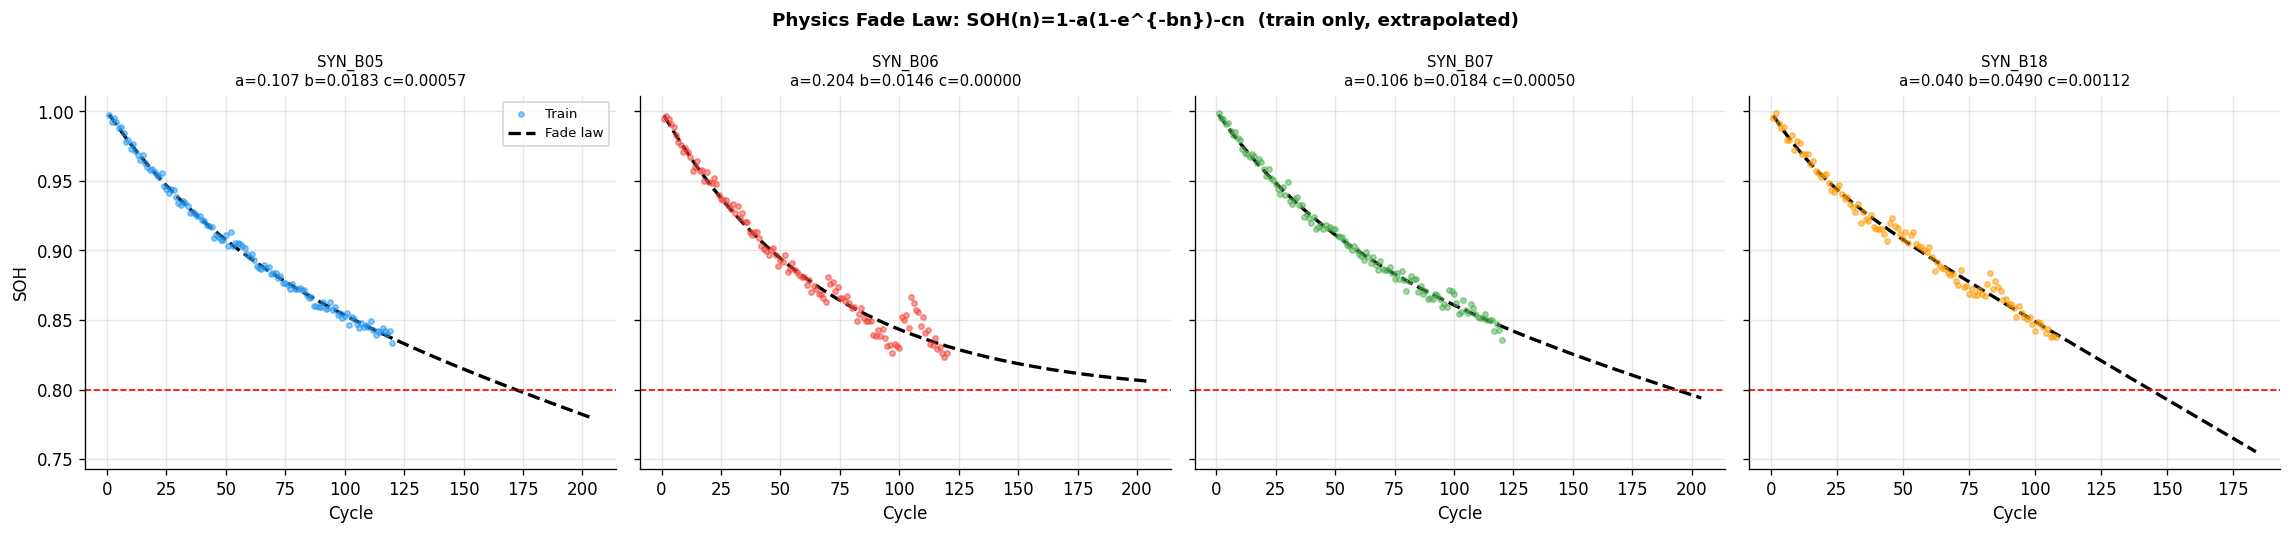

In [8]:
# CELL 8 — Physics fade law fit plot

n_b = train["battery_id"].nunique()
fig,axes=plt.subplots(1,n_b,figsize=(4.8*n_b,4.5),sharey=True)
axes=np.atleast_1d(axes)
for ax,(bid,g),col in zip(axes,train.groupby("battery_id"),COLORS):
    g=g.sort_values("cycle")
    ax.scatter(g["cycle"],g["soh"],s=10,alpha=0.5,color=col,zorder=3,label="Train")
    n_ext=np.linspace(1,g["cycle"].max()*1.7,250)
    ax.plot(n_ext,fade_model(n_ext,*fits[bid]),"k--",lw=2,label="Fade law")
    ax.axhline(EOL_THRESHOLD,color="red",ls="--",lw=1)
    a2,b2,c2=fits[bid]
    ax.set_title(f"{bid}\na={a2:.3f} b={b2:.4f} c={c2:.5f}",fontsize=9)
    ax.set_xlabel("Cycle")
axes[0].set_ylabel("SOH"); axes[0].legend(fontsize=8)
plt.suptitle("Physics Fade Law: SOH(n)=1-a(1-e^{-bn})-cn  (train only, extrapolated)",
    fontsize=11,fontweight="bold")
plt.tight_layout()
plt.savefig(OUT/"02_physics_fit.png",bbox_inches="tight",dpi=130)
plt.show()

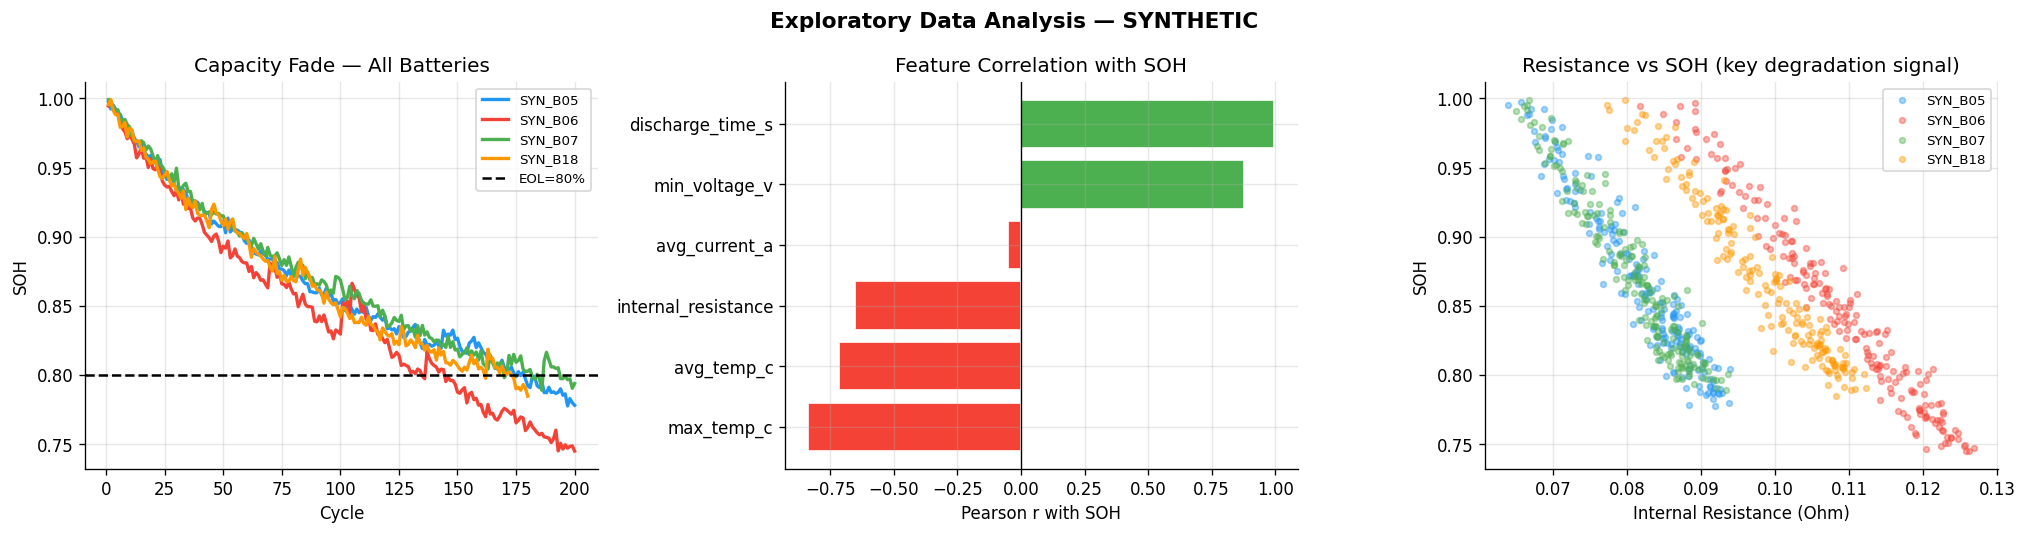

In [9]:
# CELL 9 — EDA plot

fig,axes=plt.subplots(1,3,figsize=(17,4.5))

for (bid,g),col in zip(df.groupby("battery_id"),COLORS):
    g=g.sort_values("cycle")
    axes[0].plot(g["cycle"],g["soh"],color=col,lw=2,label=bid)
axes[0].axhline(EOL_THRESHOLD,color="black",ls="--",lw=1.5,label=f"EOL={EOL_THRESHOLD:.0%}")
axes[0].set(xlabel="Cycle",ylabel="SOH",title="Capacity Fade — All Batteries")
axes[0].legend(fontsize=8)

corr=df[BASE_FEATS+["soh"]].corr()["soh"].drop("soh").sort_values()
axes[1].barh(corr.index,corr.values,
    color=["#F44336" if v<0 else "#4CAF50" for v in corr],edgecolor="white")
axes[1].axvline(0,color="black",lw=0.8)
axes[1].set(xlabel="Pearson r with SOH",title="Feature Correlation with SOH")

for (bid,g),col in zip(df.groupby("battery_id"),COLORS):
    axes[2].scatter(g["internal_resistance"],g["soh"],color=col,alpha=0.4,s=12,label=bid)
axes[2].set(xlabel="Internal Resistance (Ohm)",ylabel="SOH",
    title="Resistance vs SOH (key degradation signal)")
axes[2].legend(fontsize=8)

plt.suptitle(f"Exploratory Data Analysis — {DATA_SOURCE.upper()}",fontsize=13,fontweight="bold")
plt.tight_layout()
plt.savefig(OUT/"01_eda.png",bbox_inches="tight",dpi=130)
plt.show()

In [10]:
# CELL 10 — Sklearn baselines (Ridge / SVR / Random Forest)

def build_baselines():
    return {
        "Ridge": Pipeline([("sc",StandardScaler()),("m",Ridge(alpha=1.0))]),
        "SVR":   Pipeline([("sc",StandardScaler()),
                            ("m",SVR(kernel="rbf",C=10,epsilon=0.005))]),
        "RF":    Pipeline([("sc",StandardScaler()),
                            ("m",RandomForestRegressor(n_estimators=200,max_depth=10,
                                min_samples_leaf=3,random_state=42,n_jobs=-1))]),
    }

def get_feature_importance(pipe,feat_names):
    m=pipe.named_steps["m"]
    if hasattr(m,"feature_importances_"): vals=m.feature_importances_
    elif hasattr(m,"coef_"):              vals=np.abs(np.ravel(m.coef_))
    else: return []
    return sorted(zip(feat_names,vals),key=lambda x:-x[1])

Xtr,ytr = train[FEAT_COLS].values, train["soh"].values
Xte,yte = test[FEAT_COLS].values,  test["soh"].values

bl_metrics, bl_preds = {}, {}
best_bl_name, best_bl_mae, best_bl_pipe = None, np.inf, None

print("SKLEARN BASELINES")
print("="*55)
for name,pipe in build_baselines().items():
    pipe.fit(Xtr,ytr)
    p=pipe.predict(Xte)
    m={"test_mae":float(mean_absolute_error(yte,p)),
       "test_rmse":float(np.sqrt(mean_squared_error(yte,p)))}
    bl_metrics[name]=m; bl_preds[name]=p
    if m["test_mae"]<best_bl_mae:
        best_bl_name,best_bl_mae,best_bl_pipe=name,m["test_mae"],pipe
    print(f"{name:<6}  MAE={m['test_mae']:.4f}  RMSE={m['test_rmse']:.4f}")

phys_only=test["physics_soh_prior"].values
bl_metrics["Physics_Only"]={"test_mae":float(mean_absolute_error(yte,phys_only)),
    "test_rmse":float(np.sqrt(mean_squared_error(yte,phys_only)))}
print(f"Physics_Only  MAE={bl_metrics['Physics_Only']['test_mae']:.4f}")
print(f"\nBest baseline: {best_bl_name}  (Test MAE={best_bl_mae:.4f})")

fi=get_feature_importance(best_bl_pipe,FEAT_COLS)
if fi:
    print("\nTop-5 features:")
    for f,v in fi[:5]: print(f"  {f:<32s}: {v:.4f}")

SKLEARN BASELINES
Ridge   MAE=0.0079  RMSE=0.0103
SVR     MAE=0.0650  RMSE=0.0714
RF      MAE=0.0399  RMSE=0.0436
Physics_Only  MAE=0.0206

Best baseline: Ridge  (Test MAE=0.0079)

Top-5 features:
  discharge_time_s                : 0.0173
  physics_soh_prior               : 0.0155
  dtime_roll_mean                 : 0.0111
  res_roll_mean                   : 0.0038
  internal_resistance             : 0.0037


In [11]:
# CELL 11 — Physics-Informed LSTM definition

class SOHLSTM(nn.Module):
    def __init__(self,n_features):
        super().__init__()
        self.lstm=nn.LSTM(n_features,HIDDEN_SIZE,NUM_LAYERS,
                          batch_first=True,dropout=DROPOUT)
        self.drop=nn.Dropout(DROPOUT)
        self.head=nn.Linear(HIDDEN_SIZE,1)
    def forward(self,x):
        out,_=self.lstm(x)
        return self.head(self.drop(out[:,-1,:])).squeeze(-1)

def make_windows(df_,feat_cols,seq_len=SEQ_LEN):
    X,y,bids,cycles=[],[],[],[]
    for bid,g in df_.groupby("battery_id"):
        g=g.sort_values("cycle")
        feats=g[feat_cols].to_numpy(np.float32)
        tgt=g["soh"].to_numpy(np.float32)
        cyc=g["cycle"].to_numpy()
        for i in range(seq_len,len(g)):
            X.append(feats[i-seq_len:i]); y.append(tgt[i])
            bids.append(bid); cycles.append(cyc[i])
    return (np.array(X,np.float32),np.array(y,np.float32),
            np.array(bids),np.array(cycles))

def train_lstm_fn(X_tr,y_tr,X_va,y_va,n_features,verbose=True):
    torch.manual_seed(42)
    model=SOHLSTM(n_features)
    opt=torch.optim.Adam(model.parameters(),lr=LR)
    sched=torch.optim.lr_scheduler.ReduceLROnPlateau(opt,patience=8,factor=0.5)
    ds=TensorDataset(torch.from_numpy(X_tr),torch.from_numpy(y_tr))
    dl=DataLoader(ds,batch_size=BATCH_SIZE,shuffle=True)
    Xv=torch.from_numpy(X_va); yv=torch.from_numpy(y_va)
    best_val,best_state,bad,history=np.inf,None,0,[]
    patience=15
    for epoch in range(EPOCHS):
        model.train(); tr_loss=0.0
        for xb,yb in dl:
            opt.zero_grad(); pred=model(xb)
            mse=nn.functional.mse_loss(pred,yb)
            with torch.no_grad():
                prev=model(xb[:,:-1,:]) if xb.shape[1]>2 else None
            if prev is not None:
                viol=torch.relu(pred-prev-REGEN_ALLOW)
                mse=mse+PHYS_LAMBDA*(viol**2).mean()
            mse.backward()
            nn.utils.clip_grad_norm_(model.parameters(),1.0)
            opt.step(); tr_loss+=mse.item()*len(xb)
        tr_loss/=len(ds)
        model.eval()
        with torch.no_grad():
            val_loss=nn.functional.mse_loss(model(Xv),yv).item()
        sched.step(val_loss); history.append((tr_loss,val_loss))
        if val_loss<best_val-1e-6:
            best_val=val_loss
            best_state={k:v.clone() for k,v in model.state_dict().items()}
            bad=0
        else:
            bad+=1
            if bad>=patience:
                if verbose: print(f"  Early stop at epoch {epoch+1}")
                break
        if verbose and (epoch+1)%20==0:
            print(f"  Epoch {epoch+1:3d}/{EPOCHS}  Train:{tr_loss:.5f}  Val:{val_loss:.5f}")
    model.load_state_dict(best_state)
    return model,history

def predict_mc(model,X,n=MC_SAMPLES):
    model.train(); preds=[]
    with torch.no_grad():
        for _ in range(n): preds.append(model(torch.from_numpy(X)).numpy())
    preds=np.stack(preds)
    return preds.mean(0),preds.std(0)

print(f"LSTM ready | Input:{SEQ_LEN}x{len(FEAT_COLS)} | Hidden:{HIDDEN_SIZE}x{NUM_LAYERS}")
print(f"Loss = MSE + {PHYS_LAMBDA}*MonotonicityPenalty | MC samples={MC_SAMPLES}")

LSTM ready | Input:20x13 | Hidden:64x2
Loss = MSE + 0.1*MonotonicityPenalty | MC samples=30


In [12]:
# CELL 12 — Train LSTM

mu=train[FEAT_COLS].mean(); sd=train[FEAT_COLS].std().replace(0,1)
ntrain,nval,ntest = train.copy(),val.copy(),test.copy()
ntrain[FEAT_COLS]=(ntrain[FEAT_COLS]-mu)/sd
nval[FEAT_COLS]  =(nval[FEAT_COLS]  -mu)/sd
ntest[FEAT_COLS] =(ntest[FEAT_COLS] -mu)/sd

tv  = pd.concat([ntrain,nval]).sort_values(["battery_id","cycle"])
tvt = pd.concat([ntrain,nval,ntest]).sort_values(["battery_id","cycle"])
Xa,ya,_,_   = make_windows(ntrain,FEAT_COLS)
Xv,yv,bv,cv = make_windows(tv,   FEAT_COLS)
Xt,yt,bt,ct = make_windows(tvt,  FEAT_COLS)

val_keys  = set(zip(val["battery_id"], val["cycle"]))
test_keys = set(zip(test["battery_id"],test["cycle"]))
vm = np.array([(b,c) in val_keys  for b,c in zip(bv,cv)])
tm = np.array([(b,c) in test_keys for b,c in zip(bt,ct)])

print(f"Windows -> Train:{len(Xa)}  Val:{vm.sum()}  Test:{tm.sum()}")
print(f"Training Physics-Informed LSTM (Loss=MSE+{PHYS_LAMBDA}*MonotonicityPenalty)...\n")

lstm_model, history = train_lstm_fn(Xa,ya,Xv[vm],yv[vm],len(FEAT_COLS),verbose=True)
print("\nTraining complete")

Windows -> Train:388  Val:156  Test:156
Training Physics-Informed LSTM (Loss=MSE+0.1*MonotonicityPenalty)...

  Epoch  20/100  Train:0.00587  Val:0.00030
  Early stop at epoch 40

Training complete


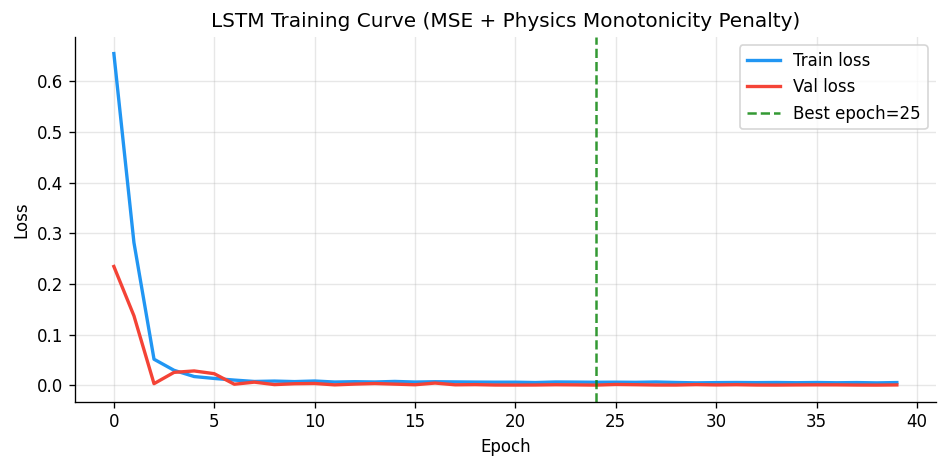

Best val loss: 0.000146 at epoch 25  (ran 40 epochs)


In [13]:
# CELL 13 — Training curve

tr_l=[h[0] for h in history]; va_l=[h[1] for h in history]
best_ep=int(np.argmin(va_l))
fig,ax=plt.subplots(figsize=(8,4))
ax.plot(tr_l,label="Train loss",color="#2196F3",lw=2)
ax.plot(va_l,label="Val loss",  color="#F44336",lw=2)
ax.axvline(best_ep,color="green",ls="--",alpha=0.8,label=f"Best epoch={best_ep+1}")
ax.set(xlabel="Epoch",ylabel="Loss",
    title="LSTM Training Curve (MSE + Physics Monotonicity Penalty)")
ax.legend(); plt.tight_layout()
plt.savefig(OUT/"04_training_curve.png",bbox_inches="tight",dpi=130)
plt.show()
print(f"Best val loss: {min(va_l):.6f} at epoch {best_ep+1}  (ran {len(history)} epochs)")

In [14]:
# CELL 14 — LSTM evaluation

mean_pred,std_pred=predict_mc(lstm_model,Xt[tm])
lstm_m={
    "test_mae":float(mean_absolute_error(yt[tm],mean_pred)),
    "test_rmse":float(np.sqrt(mean_squared_error(yt[tm],mean_pred))),
    "mean_pred_std":float(std_pred.mean()),
}
print("PHYSICS-INFORMED LSTM — TEST RESULTS")
print("="*42)
print(f"  Test MAE       : {lstm_m['test_mae']:.4f}")
print(f"  Test RMSE      : {lstm_m['test_rmse']:.4f}")
print(f"  Avg uncertainty: +/-{2*lstm_m['mean_pred_std']:.4f} (2-sigma MC dropout)")

all_m={**bl_metrics,"LSTM_Physics":lstm_m}

PHYSICS-INFORMED LSTM — TEST RESULTS
  Test MAE       : 0.0205
  Test RMSE      : 0.0252
  Avg uncertainty: +/-0.1345 (2-sigma MC dropout)


In [15]:
# CELL 15 — RUL estimation (4-method fallback, no more N/A)

def rul_from_traj(cycles,soh_pred,current_cycle,eol_thr,phys_fallback=None):
    cycles,soh_pred=np.asarray(cycles,float),np.asarray(soh_pred,float)
    mask=cycles>=current_cycle; c,s=cycles[mask],soh_pred[mask]
    if len(c)==0:
        return float(phys_fallback) if phys_fallback is not None else np.nan

    # Method 1: direct crossing
    below=np.where(s<eol_thr)[0]
    if len(below)>0:
        return float(c[below[0]]-current_cycle)

    # Method 2: extrapolate using all points
    if len(s)>=2:
        slope_all=np.polyfit(c,s,1)[0]
        if slope_all<0:
            return float(c[-1]+(s[-1]-eol_thr)/(-slope_all)-current_cycle)

    # Method 3: extrapolate using last 5 points
    if len(s)>=5:
        slope_tail=np.polyfit(c[-5:],s[-5:],1)[0]
        if slope_tail<0:
            return float(c[-1]+(s[-1]-eol_thr)/(-slope_tail)-current_cycle)

    # Method 4: physics fallback
    if phys_fallback is not None:
        return float(phys_fallback)
    return np.nan


lstm_rul_d, lstm_method_d = {}, {}
for bid in np.unique(bt[tm]):
    mb=(bt==bid)&tm; sc=train[train["battery_id"]==bid]["cycle"].max()
    raw=rul_from_traj(ct[mb],mean_pred[bt[tm]==bid],sc,EOL_THRESHOLD,
                       phys_fallback=phys_rul_d.get(bid))
    lstm_rul_d[bid]=raw
    if raw==phys_rul_d.get(bid): lstm_method_d[bid]="physics fallback"
    elif np.isfinite(raw):       lstm_method_d[bid]="trajectory"
    else:                        lstm_method_d[bid]="N/A"

print("RUL COMPARISON — From End of Training Data")
print("="*78)
print(f"{'Battery':<10} {'True':>6} {'Physics':>8} {'PhysErr':>8} "
      f"{'LSTM':>8} {'LSTMErr':>8}  {'Method'}")
print("-"*78)
for bid in sorted(true_rul_d):
    tr=true_rul_d[bid]; ph=phys_rul_d.get(bid,np.nan); lm=lstm_rul_d.get(bid,np.nan)
    pe=abs(tr-ph); le=abs(tr-lm) if np.isfinite(lm) else np.nan
    print(f"{bid:<10} {tr:>6.1f} {ph:>8.1f} {pe:>8.1f} "
          f"{lm:>8.1f} {le:>8.1f}  {lstm_method_d.get(bid,'?')}")

RUL COMPARISON — From End of Training Data
Battery      True  Physics  PhysErr     LSTM  LSTMErr  Method
------------------------------------------------------------------------------
SYN_B05      55.0     51.8      3.2     41.0     14.0  trajectory
SYN_B06      15.0    144.9    129.9     41.0     26.0  trajectory
SYN_B07      50.0     73.1     23.1     48.0      2.0  trajectory
SYN_B18      54.0     35.6     18.4     37.0     17.0  trajectory


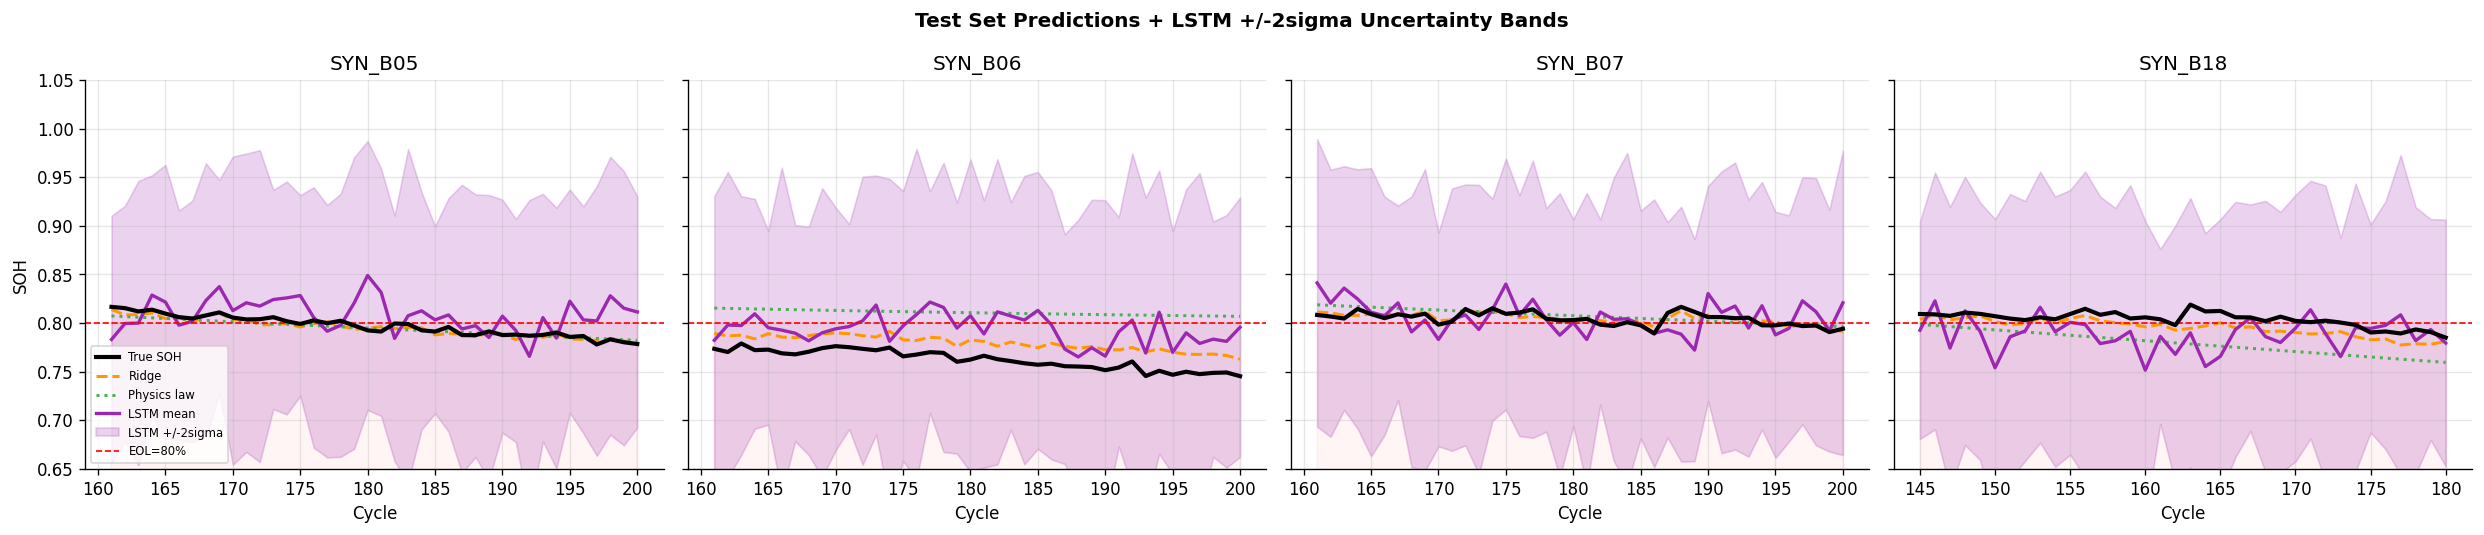

In [16]:
# CELL 16 — Test prediction plot + LSTM uncertainty bands

bids=sorted(test["battery_id"].unique())
fig,axes=plt.subplots(1,len(bids),figsize=(5.2*len(bids),4.5),sharey=True)
axes=np.atleast_1d(axes)
for ax,bid,col in zip(axes,bids,COLORS):
    g=test[test["battery_id"]==bid].sort_values("cycle")
    te_m=(test["battery_id"]==bid).values
    bt_m=(bt==bid)&tm
    ax.plot(g["cycle"],g["soh"],"k-",lw=2.5,label="True SOH",zorder=5)
    ax.plot(g["cycle"],bl_preds[best_bl_name][te_m],"--",lw=1.8,
        color="#FF9800",label=best_bl_name)
    ax.plot(g["cycle"],g["physics_soh_prior"],":",lw=1.8,
        color="#4CAF50",label="Physics law")
    if bt_m.sum()>0:
        c_l=ct[bt_m]; m_l=mean_pred[bt[tm]==bid]; s_l=std_pred[bt[tm]==bid]
        o=np.argsort(c_l)
        ax.plot(c_l[o],m_l[o],"-",lw=2,color="#9C27B0",label="LSTM mean")
        ax.fill_between(c_l[o],m_l[o]-2*s_l[o],m_l[o]+2*s_l[o],
            alpha=0.2,color="#9C27B0",label="LSTM +/-2sigma")
    ax.axhline(EOL_THRESHOLD,color="red",ls="--",lw=1,label=f"EOL={EOL_THRESHOLD:.0%}")
    ax.fill_between([g["cycle"].min(),g["cycle"].max()],0,EOL_THRESHOLD,alpha=0.04,color="red")
    ax.set(title=bid,xlabel="Cycle",ylim=(min(0.65,yte.min()-0.05),1.05))
axes[0].set_ylabel("SOH"); axes[0].legend(fontsize=7,loc="lower left")
plt.suptitle("Test Set Predictions + LSTM +/-2sigma Uncertainty Bands",
    fontsize=12,fontweight="bold")
plt.tight_layout()
plt.savefig(OUT/"03_test_predictions.png",bbox_inches="tight",dpi=130)
plt.show()

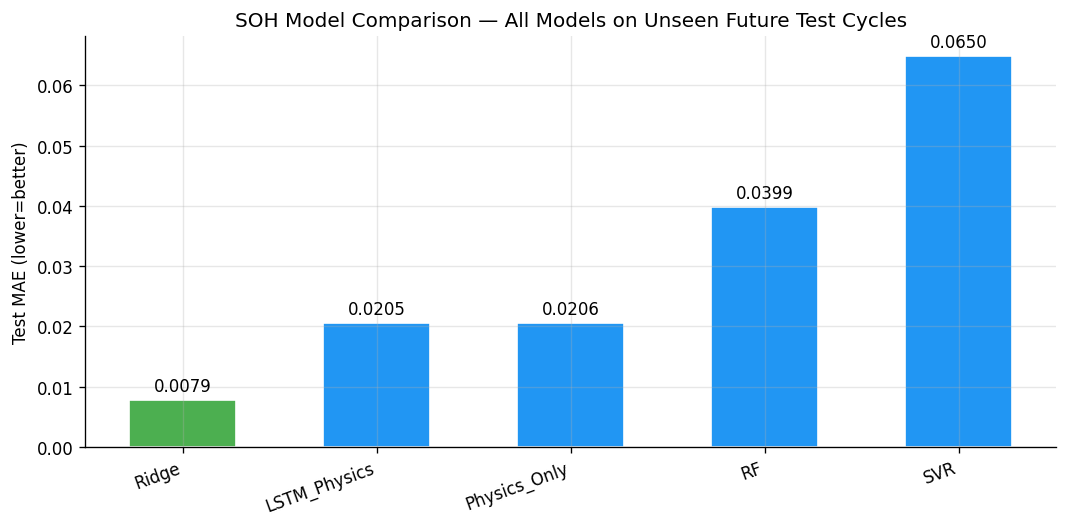

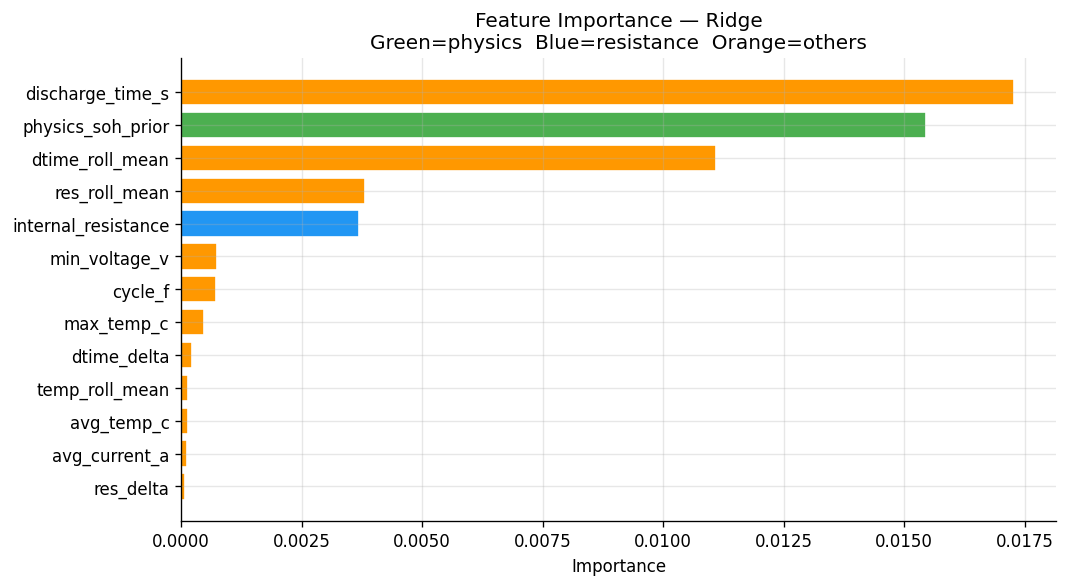

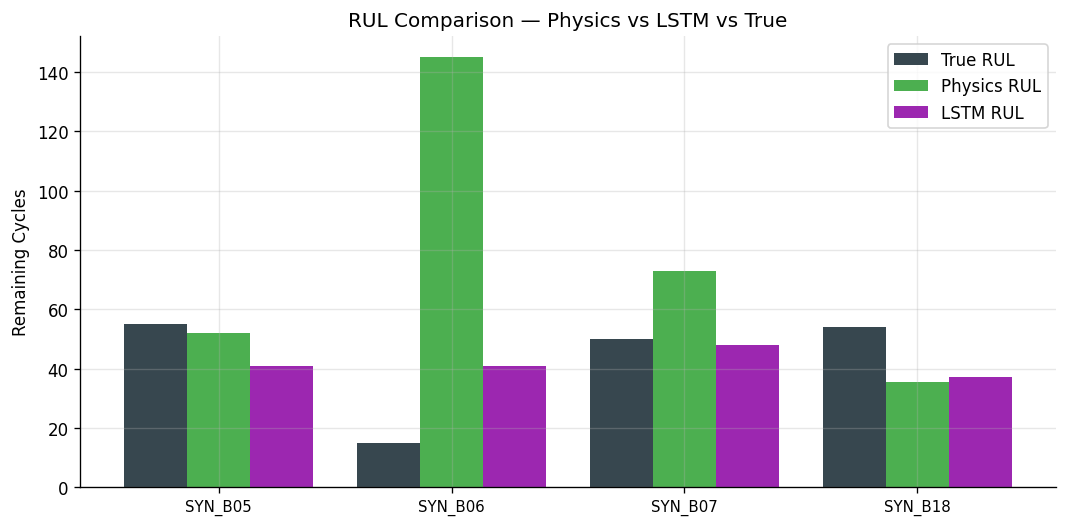

In [17]:
# CELL 17 — Model comparison + feature importance + RUL bar chart

# Model MAE comparison
ns=sorted(all_m,key=lambda k:all_m[k]["test_mae"])
ms=[all_m[n]["test_mae"] for n in ns]
fig,ax=plt.subplots(figsize=(9,4.5))
cols=["#4CAF50" if n==ns[0] else "#2196F3" for n in ns]
bars=ax.bar(ns,ms,color=cols,edgecolor="white",width=0.55)
ax.bar_label(bars,fmt="%.4f",padding=3,fontsize=10)
ax.set(ylabel="Test MAE (lower=better)",
    title="SOH Model Comparison — All Models on Unseen Future Test Cycles")
plt.xticks(rotation=20,ha="right"); plt.tight_layout()
plt.savefig(OUT/"05_model_comparison.png",bbox_inches="tight",dpi=130)
plt.show()

# Feature importance
fig,ax=plt.subplots(figsize=(9,5))
if fi:
    feats,imps=zip(*fi)
    bar_c=["#4CAF50" if "physics" in f else "#2196F3" if "resist" in f else "#FF9800" for f in feats]
    ax.barh(feats,imps,color=bar_c,edgecolor="white")
    ax.invert_yaxis()
    ax.set(xlabel="Importance",
        title=f"Feature Importance — {best_bl_name}\n"
              "Green=physics  Blue=resistance  Orange=others")
plt.tight_layout()
plt.savefig(OUT/"06_feature_importance.png",bbox_inches="tight",dpi=130)
plt.show()

# RUL comparison
bids_r=sorted(true_rul_d); x=np.arange(len(bids_r)); w=0.27
fig,ax=plt.subplots(figsize=(9,4.5))
ax.bar(x-w,[true_rul_d[b] for b in bids_r],          w,label="True RUL",   color="#37474F")
ax.bar(x,  [phys_rul_d.get(b,0) for b in bids_r],    w,label="Physics RUL",color="#4CAF50")
ax.bar(x+w,[lstm_rul_d.get(b,0) or 0 for b in bids_r],w,label="LSTM RUL",  color="#9C27B0")
ax.set_xticks(x); ax.set_xticklabels(bids_r,fontsize=9)
ax.set(title="RUL Comparison — Physics vs LSTM vs True",ylabel="Remaining Cycles")
ax.legend(); plt.tight_layout()
plt.savefig(OUT/"07_rul_comparison.png",bbox_inches="tight",dpi=130)
plt.show()

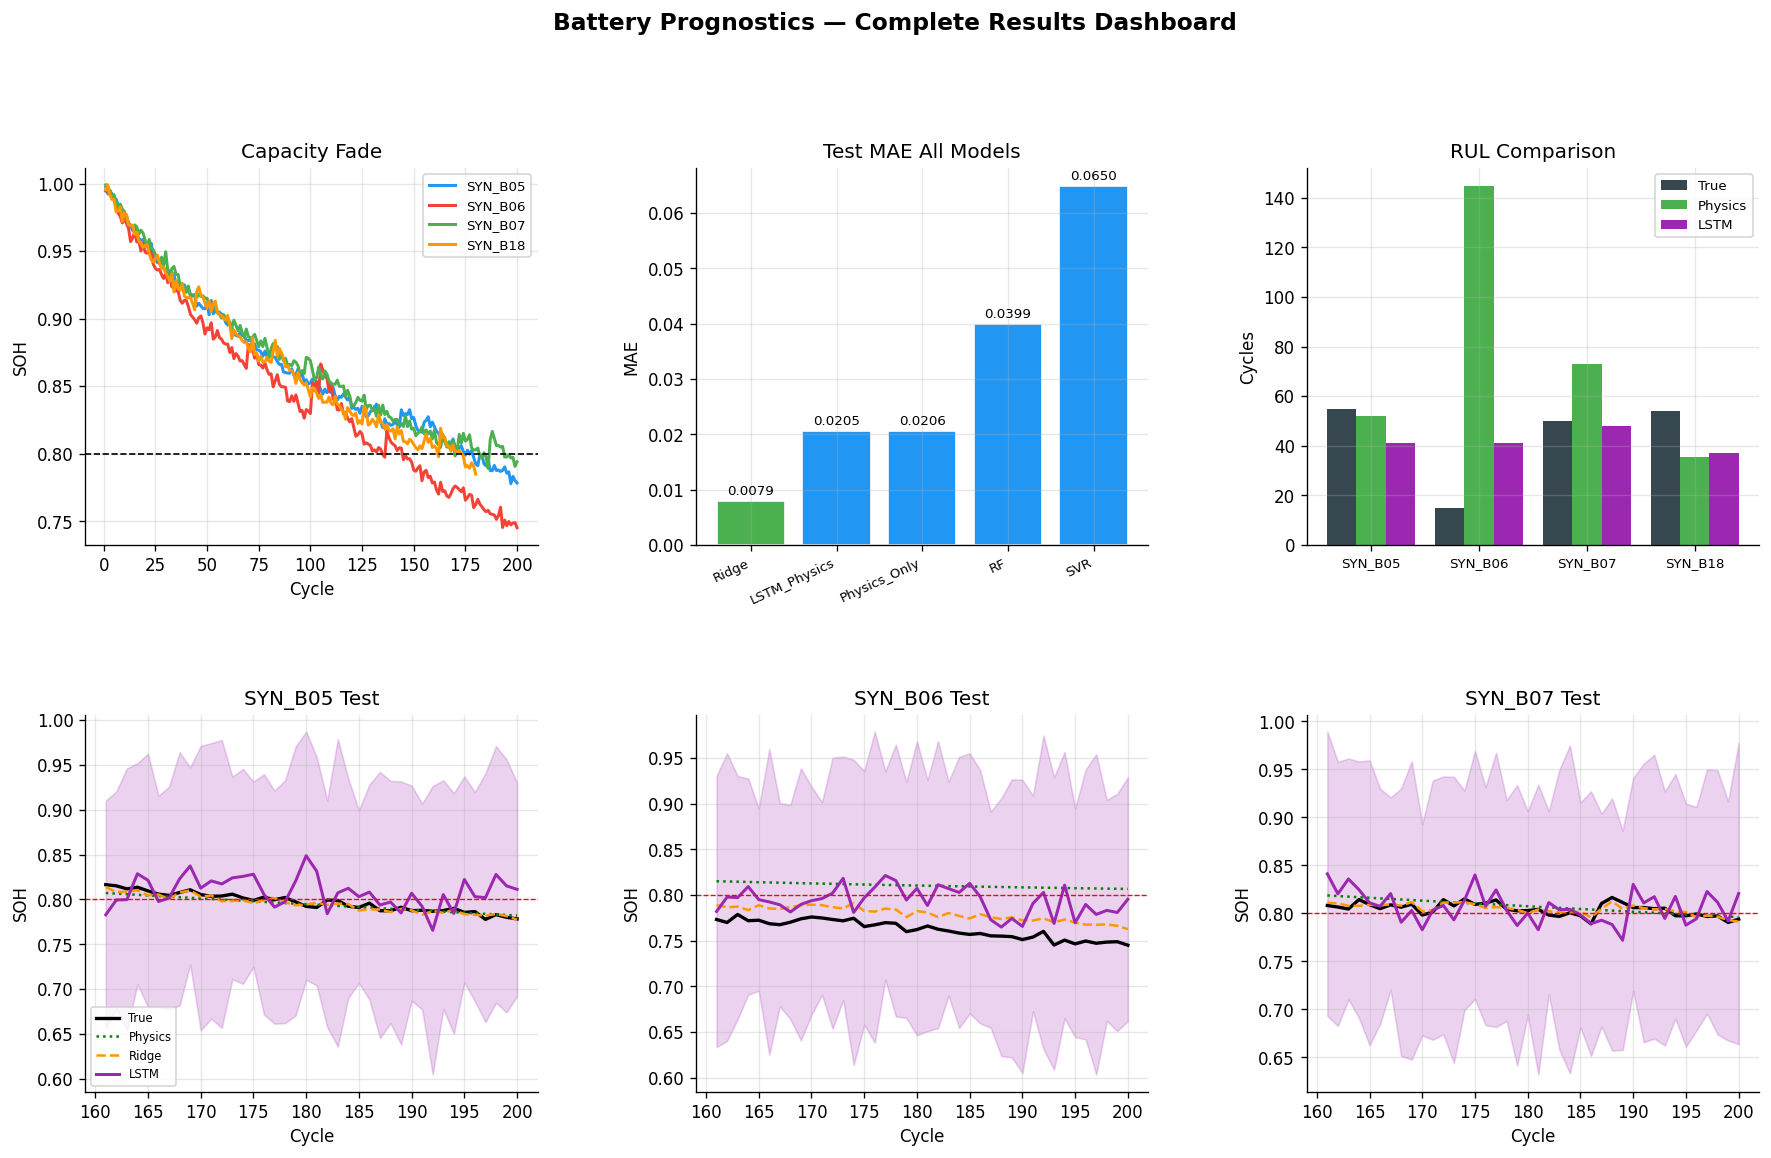

In [18]:
# CELL 18 — Final dashboard (combines everything in one figure)

fig=plt.figure(figsize=(18,10))
gs=gridspec.GridSpec(2,3,figure=fig,hspace=0.45,wspace=0.35)

ax_f=fig.add_subplot(gs[0,0])
for (bid,g),col in zip(df.groupby("battery_id"),COLORS):
    g=g.sort_values("cycle"); ax_f.plot(g["cycle"],g["soh"],color=col,lw=1.8,label=bid)
ax_f.axhline(EOL_THRESHOLD,color="black",ls="--",lw=1)
ax_f.set(title="Capacity Fade",xlabel="Cycle",ylabel="SOH"); ax_f.legend(fontsize=8)

ax_m=fig.add_subplot(gs[0,1])
b_=ax_m.bar(ns,ms,color=cols,edgecolor="white")
ax_m.bar_label(b_,fmt="%.4f",fontsize=8,padding=2)
ax_m.set(title="Test MAE All Models",ylabel="MAE")
plt.setp(ax_m.xaxis.get_majorticklabels(),rotation=25,ha="right",fontsize=8)

ax_r=fig.add_subplot(gs[0,2])
ax_r.bar(x-w,[true_rul_d[b] for b in bids_r],          w,label="True",   color="#37474F")
ax_r.bar(x,  [phys_rul_d.get(b,0) for b in bids_r],    w,label="Physics",color="#4CAF50")
ax_r.bar(x+w,[lstm_rul_d.get(b,0) or 0 for b in bids_r],w,label="LSTM",  color="#9C27B0")
ax_r.set_xticks(x); ax_r.set_xticklabels(bids_r,fontsize=8)
ax_r.set(title="RUL Comparison",ylabel="Cycles"); ax_r.legend(fontsize=8)

for i,(bid,col) in enumerate(zip(sorted(test["battery_id"].unique())[:3],COLORS)):
    ax=fig.add_subplot(gs[1,i])
    g=test[test["battery_id"]==bid].sort_values("cycle")
    te_m=(test["battery_id"]==bid).values; bt_m=(bt==bid)&tm
    ax.plot(g["cycle"],g["soh"],"k-",lw=2,label="True")
    ax.plot(g["cycle"],g["physics_soh_prior"],"g:",lw=1.5,label="Physics")
    ax.plot(g["cycle"],bl_preds[best_bl_name][te_m],"--",color="#FF9800",lw=1.5,label=best_bl_name)
    if bt_m.sum()>0:
        c_l=ct[bt_m]; m_l=mean_pred[bt[tm]==bid]; s_l=std_pred[bt[tm]==bid]
        o=np.argsort(c_l)
        ax.plot(c_l[o],m_l[o],color="#9C27B0",lw=1.8,label="LSTM")
        ax.fill_between(c_l[o],m_l[o]-2*s_l[o],m_l[o]+2*s_l[o],alpha=0.2,color="#9C27B0")
    ax.axhline(EOL_THRESHOLD,color="red",ls="--",lw=0.8)
    ax.set(title=f"{bid} Test",xlabel="Cycle",ylabel="SOH")
    if i==0: ax.legend(fontsize=7,loc="lower left")

plt.suptitle("Battery Prognostics — Complete Results Dashboard",fontsize=14,fontweight="bold",y=1.01)
plt.savefig(OUT/"08_dashboard.png",bbox_inches="tight",dpi=130)
plt.show()

In [19]:
# CELL 19 — Metrics tables, 3 example cases, save JSON + zip download

soh_df=pd.DataFrame([{"Model":n,"Test MAE":round(m["test_mae"],4),
    "Test RMSE":round(m["test_rmse"],4)} for n,m in all_m.items()]
    ).sort_values("Test MAE").reset_index(drop=True)

rul_df=pd.DataFrame([{
    "Battery":bid,
    "True RUL":round(true_rul_d[bid],1),
    "Physics RUL":round(phys_rul_d.get(bid,np.nan),1),
    "Physics Err":round(abs(true_rul_d[bid]-phys_rul_d.get(bid,0)),1),
    "LSTM RUL":round(lstm_rul_d.get(bid,np.nan),1) if np.isfinite(lstm_rul_d.get(bid,np.nan)) else "N/A",
    "LSTM Err":round(abs(true_rul_d[bid]-(lstm_rul_d.get(bid) or 0)),1) if np.isfinite(lstm_rul_d.get(bid,np.nan)) else "N/A",
    "LSTM Method":lstm_method_d.get(bid,"N/A"),
} for bid in sorted(true_rul_d)])

print("SOH MODEL COMPARISON")
display(soh_df)
print("\nRUL ESTIMATION RESULTS")
display(rul_df)

# 3 example cases
examples=[]
for i,bid in enumerate(sorted(test["battery_id"].unique())[:3]):
    g=test[test["battery_id"]==bid].sort_values("cycle")
    row=g.iloc[len(g)//2]
    bl_p=float(best_bl_pipe.predict(row[FEAT_COLS].to_frame().T)[0])
    bt_m=(bt==bid)&tm; ct_m=ct[bt_m]
    mp_m=mean_pred[bt[tm]==bid]; sp_m=std_pred[bt[tm]==bid]
    idx=np.argmin(np.abs(ct_m-row["cycle"]))
    examples.append({
        "example_no":i+1,"battery_id":bid,"input_cycle":int(row["cycle"]),
        "true_soh":round(float(row["soh"]),4),
        f"{best_bl_name}_pred":round(bl_p,4),
        "lstm_mean":round(float(mp_m[idx]),4),
        "lstm_2sigma":round(float(2*sp_m[idx]),4),
        "physics_rul":round(phys_rul_d[bid],1),
        "lstm_rul":round(float(lstm_rul_d.get(bid,np.nan)),1),
        "true_rul":round(true_rul_d[bid],1),
        "lstm_method":lstm_method_d.get(bid),
    })

with open(OUT/"example_cases.json","w") as f: json.dump(examples,f,indent=2,default=float)

# metrics.json
all_results={
    "data_source":DATA_SOURCE,"eol_threshold":EOL_THRESHOLD,
    "split":{"train":len(train),"val":len(val),"test":len(test)},
    "fade_law_params":{k:list(map(float,v)) for k,v in fits.items()},
    "soh_test_metrics":{k:{m2:float(v2) for m2,v2 in mv.items()} for k,mv in all_m.items()},
    "rul_results":{bid:{
        "true_rul":true_rul_d[bid],"physics_rul":phys_rul_d.get(bid),
        "physics_err":abs(true_rul_d[bid]-phys_rul_d.get(bid,0)),
        "lstm_rul":lstm_rul_d.get(bid),
        "lstm_err":abs(true_rul_d[bid]-(lstm_rul_d.get(bid) or 0)) if np.isfinite(lstm_rul_d.get(bid,np.nan)) else None,
        "lstm_method":lstm_method_d.get(bid),
    } for bid in true_rul_d}
}
with open(OUT/"metrics.json","w") as f: json.dump(all_results,f,indent=2,default=float)

print(f"\nSaved: metrics.json, example_cases.json + 6 PNG plots -> {OUT}")
for p in sorted(OUT.iterdir()):
    print(f"  {p.name:<28s} {p.stat().st_size//1024} KB")

SOH MODEL COMPARISON


,Model,Test MAE,Test RMSE
0,Ridge,0.0079,0.0103
1,LSTM_Physics,0.0205,0.0252
2,Physics_Only,0.0206,0.0281
3,RF,0.0399,0.0436
4,SVR,0.0650,0.0714



RUL ESTIMATION RESULTS


,Battery,True RUL,Physics RUL,Physics Err,LSTM RUL,LSTM Err,LSTM Method
0,SYN_B05,55.0,51.8,3.2,41.0,14.0,trajectory
1,SYN_B06,15.0,144.9,129.9,41.0,26.0,trajectory
2,SYN_B07,50.0,73.1,23.1,48.0,2.0,trajectory
3,SYN_B18,54.0,35.6,18.4,37.0,17.0,trajectory



Saved: metrics.json, example_cases.json + 6 PNG plots -> /content/battery_outputs
  01_eda.png                   211 KB
  02_physics_fit.png           132 KB
  03_test_predictions.png      239 KB
  04_training_curve.png        44 KB
  05_model_comparison.png      47 KB
  06_feature_importance.png    58 KB
  07_rul_comparison.png        31 KB
  08_dashboard.png             308 KB
  example_cases.json           0 KB
  metrics.json                 1 KB


In [20]:
# CELL 20 — Zip everything and download

shutil.make_archive("/content/battery_results","zip",OUT)
print(f"ZIP ready: /content/battery_results.zip "
      f"({Path('/content/battery_results.zip').stat().st_size//1024} KB)")

from google.colab import files
files.download("/content/battery_results.zip")

print("\n" + "="*55)
print("DONE")
print("="*55)
print('''
battery_results.zip contains:
  01_eda.png                EDA: fade curves, correlations, resistance vs SOH
  02_physics_fit.png         Physics fade law fitted on training data
  03_test_predictions.png    True SOH vs all models + LSTM uncertainty bands
  04_training_curve.png      LSTM train/val loss per epoch
  05_model_comparison.png    MAE bar chart, all models ranked
  06_feature_importance.png  Which features matter most
  07_rul_comparison.png      True vs Physics vs LSTM RUL
  08_dashboard.png           Complete summary in one figure
  metrics.json               All MAE/RMSE/RUL numbers
  example_cases.json         3 sample input-to-output cases
''')

ZIP ready: /content/battery_results.zip (993 KB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


DONE

battery_results.zip contains:
  01_eda.png                EDA: fade curves, correlations, resistance vs SOH
  02_physics_fit.png         Physics fade law fitted on training data
  03_test_predictions.png    True SOH vs all models + LSTM uncertainty bands
  04_training_curve.png      LSTM train/val loss per epoch
  05_model_comparison.png    MAE bar chart, all models ranked
  06_feature_importance.png  Which features matter most
  07_rul_comparison.png      True vs Physics vs LSTM RUL
  08_dashboard.png           Complete summary in one figure
  metrics.json               All MAE/RMSE/RUL numbers
  example_cases.json         3 sample input-to-output cases

